# KinoRank

**Autor:** Ítalo Leal (`@Lealwbs`)  
**Fluxo:** DuckDB SQL / PySpark $\rightarrow$ Estágio 1 (ALS + FAISS + RRF) $\rightarrow$ Estágio 2 (LightGBM LambdaRank + TreeSHAP + MMR) $\rightarrow$ Estágio 3 (Agente LLM com trava de catálogo).

### Sumário
1. **Dados:** distribuição de popularidade (cauda longa) e notas no MovieLens.
2. **Validação:** verificação do split estritamente temporal por usuário (zero vazamento de futuro).
3. **Features:** SQL analítico no DuckDB com Window Functions, média bayesiana e decaimento temporal.
4. **Modelo:** importância das 15 variáveis no LightGBM LambdaRank e execução conversacional.
5. **Resultados:** comparativo offline das 5 abordagens em precisão, cobertura, diversidade e latência.

In [1]:
import sys
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.agent.tools import KinoRankAgentOrchestrator
from src.config import settings
from src.data.temporal_split import verify_zero_temporal_leakage
from src.ranking.lgbm_ranker import FEATURE_NAMES

plt.rcParams.update({
    "figure.facecolor": "#09090b",
    "axes.facecolor": "#18181b",
    "axes.edgecolor": "#27272a",
    "axes.labelcolor": "#e4e4e7",
    "text.color": "#f4f4f5",
    "xtick.color": "#a1a1aa",
    "ytick.color": "#a1a1aa",
    "grid.color": "#27272a",
})
print(f"Project Root: {PROJECT_ROOT}")

Project Root: /home/antigravity/Lealwbs/kinorank


/home/antigravity/Lealwbs/kinorank/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Dados

Em catálogos reais, poucos títulos concentram a maior parte das avaliações, enquanto mais de 70% dos filmes ficam na cauda longa.

/tmp/ipykernel_794/4084038146.py:14: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  """).df()
/tmp/ipykernel_794/4084038146.py:14: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  """).df()


,total_interactions,unique_users,rated_movies,global_mean_rating,global_std_rating,min_date,max_date
0,100836,610,9724,3.502,1.043,1996-03-29 18:36:55+00:00,2018-09-24 14:27:30+00:00


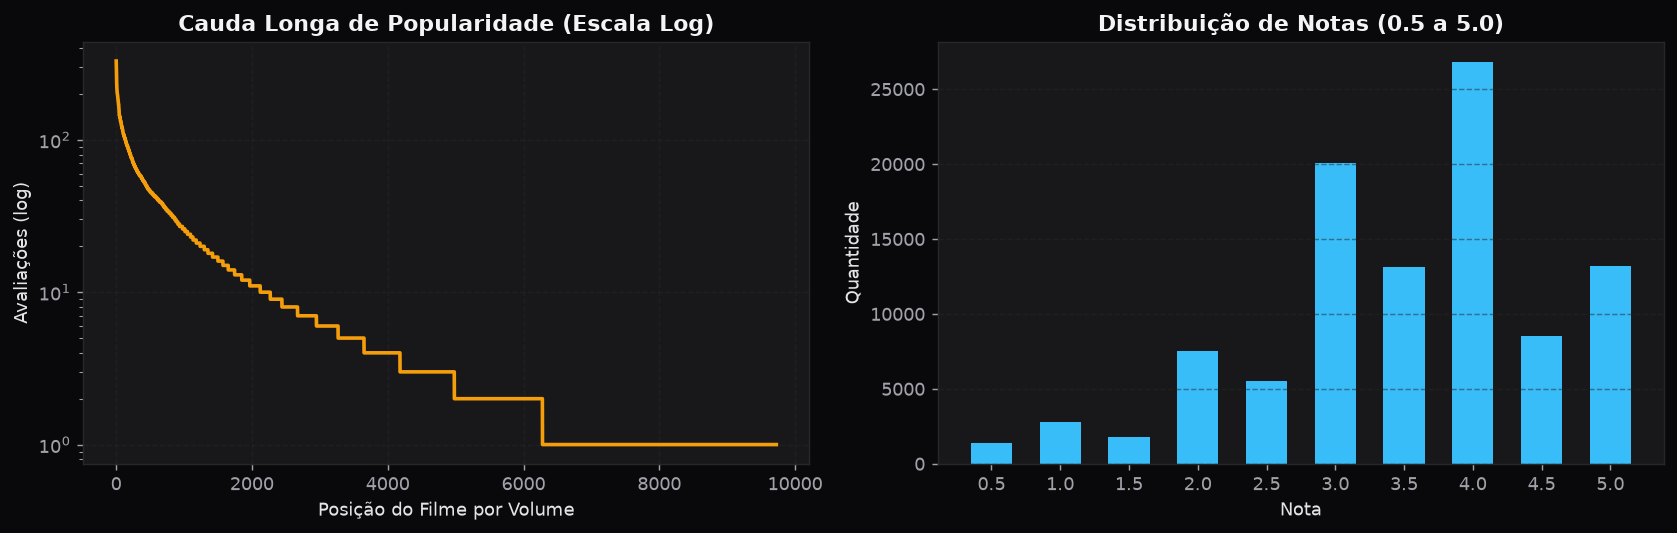

In [2]:
con = duckdb.connect(database=":memory:")
bronze_ratings = (settings.bronze_dir / "ratings.parquet").as_posix()

eda_summary = con.execute(f"""
    SELECT
        COUNT(*) AS total_interactions,
        COUNT(DISTINCT user_id) AS unique_users,
        COUNT(DISTINCT movie_id) AS rated_movies,
        ROUND(AVG(rating), 3) AS global_mean_rating,
        ROUND(STDDEV_SAMP(rating), 3) AS global_std_rating,
        MIN(interaction_dt) AS min_date,
        MAX(interaction_dt) AS max_date
    FROM '{bronze_ratings}'
""").df()
display(eda_summary)

item_pop_df = con.execute(f"""
    SELECT
        movie_id,
        COUNT(*) AS rating_count,
        AVG(rating) AS avg_rating
    FROM '{bronze_ratings}'
    GROUP BY movie_id
    ORDER BY rating_count DESC
""").df()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), dpi=130)
axes[0].plot(np.arange(1, len(item_pop_df) + 1), item_pop_df["rating_count"], color="#f59e0b", lw=2)
axes[0].set_yscale("log")
axes[0].set_title("Cauda Longa de Popularidade (Escala Log)", fontweight="bold")
axes[0].set_xlabel("Posição do Filme por Volume")
axes[0].set_ylabel("Avaliações (log)")
axes[0].grid(True, linestyle="--", alpha=0.5)

rating_dist = con.execute(f"""
    SELECT rating, COUNT(*) AS cnt
    FROM '{bronze_ratings}'
    GROUP BY rating ORDER BY rating
""").df()
axes[1].bar(rating_dist["rating"].astype(str), rating_dist["cnt"], color="#38bdf8", width=0.6)
axes[1].set_title("Distribuição de Notas (0.5 a 5.0)", fontweight="bold")
axes[1].set_xlabel("Nota")
axes[1].set_ylabel("Quantidade")
axes[1].grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

## Validação

As interações de cada usuário são ordenadas por `timestamp` e divididas em `70% treino`, `15% validação` e `15% teste`. A verificação abaixo confirma que nenhum evento futuro vaza para o conjunto de treino.

In [3]:
leakage_report = verify_zero_temporal_leakage()
for k, v in leakage_report.items():
    print(f"{k}: {v}")
assert leakage_report["temporal_violations"] == 0
assert leakage_report["pair_overlap_violations"] == 0

train_count: 70316
val_count: 15098
test_count: 15422
temporal_violations: 0
pair_overlap_violations: 0


## Features

Inspeção das tabelas da camada Gold geradas via DuckDB SQL (`ROW_NUMBER`, `LAG`, `AVG OVER`, `RANK`, média bayesiana e decaimento exponencial no tempo).

In [4]:
gold_items_pq = (settings.gold_dir / "item_features.parquet").as_posix()
gold_users_pq = (settings.gold_dir / "user_features.parquet").as_posix()

top_bayesian_items = con.execute(f"""
    SELECT
        popularity_rank,
        movie_id,
        clean_title,
        release_year,
        director,
        rating_count,
        ROUND(raw_mean_rating, 3) AS raw_mean,
        ROUND(bayesian_rating, 3) AS bayesian_rating,
        ROUND(recent_popularity_score, 2) AS decayed_pop
    FROM '{gold_items_pq}'
    ORDER BY popularity_rank ASC
    LIMIT 10
""").df()
display(top_bayesian_items)

sample_users = con.execute(f"""
    SELECT
        user_id,
        total_interactions,
        mean_rating,
        latest_rolling_5_rating,
        avg_inter_event_hours,
        top_genres,
        favorite_decades,
        profile_summary_text
    FROM '{gold_users_pq}'
    LIMIT 5
""").df()
display(sample_users)

,popularity_rank,movie_id,clean_title,release_year,director,rating_count,raw_mean,bayesian_rating,decayed_pop
0,1,2571,The Matrix,1999,Lana Wachowski,247,4.194,4.156,15.11
1,2,318,The Shawshank Redemption,1994,Frank Darabont,264,4.413,4.365,13.71
2,3,79132,Inception,2010,Christopher Nolan,118,4.055,3.995,13.50
3,4,356,Forrest Gump,1994,Robert Zemeckis,280,4.161,4.128,13.37
4,5,7153,The Lord of the Rings: The Return of the King,2003,Unknown,165,4.133,4.082,13.13
5,6,4993,The Lord of the Rings: The Fellowship of the Ring,2001,Peter Jackson,170,4.112,4.064,12.28
6,7,5952,The Lord of the Rings: The Two Towers,2002,Unknown,159,4.041,3.996,12.19
7,8,260,Star Wars: Episode IV - A New Hope,1977,George Lucas,218,4.204,4.160,10.85
8,9,58559,The Dark Knight,2008,Christopher Nolan,119,4.223,4.144,10.78
9,10,2959,Fight Club,1999,David Fincher,183,4.270,4.214,10.67


,user_id,total_interactions,mean_rating,latest_rolling_5_rating,avg_inter_event_hours,top_genres,favorite_decades,profile_summary_text
0,1,162,4.3889,4.8,0.00,"[Adventure, Action, Comedy, Children]","[1990, 1980, 1970]","User #1 (162 interactions, avg rating 4.39/5.0..."
1,2,20,3.8500,4.3,0.00,"[Drama, Crime, Action, Comedy]","[2010, 2000, 1990]","User #2 (20 interactions, avg rating 3.85/5.0)..."
2,3,27,3.1481,4.6,0.01,"[Sci-Fi, Action, Horror, Thriller]","[1980, 1970, 1960]","User #3 (27 interactions, avg rating 3.15/5.0)..."
3,4,151,3.7086,3.6,77.35,"[Drama, Comedy, Romance, Crime]","[1990, 1980, 1950]","User #4 (151 interactions, avg rating 3.71/5.0..."
4,5,30,3.6333,4.0,0.00,"[Drama, Children, Comedy, Fantasy]","[1990, 1930, 1980]","User #5 (30 interactions, avg rating 3.63/5.0)..."


## Modelo

Importância por ganho das 15 variáveis no `LightGBM (objective="lambdarank")` e exemplo de consulta conversacional nos 3 estágios.

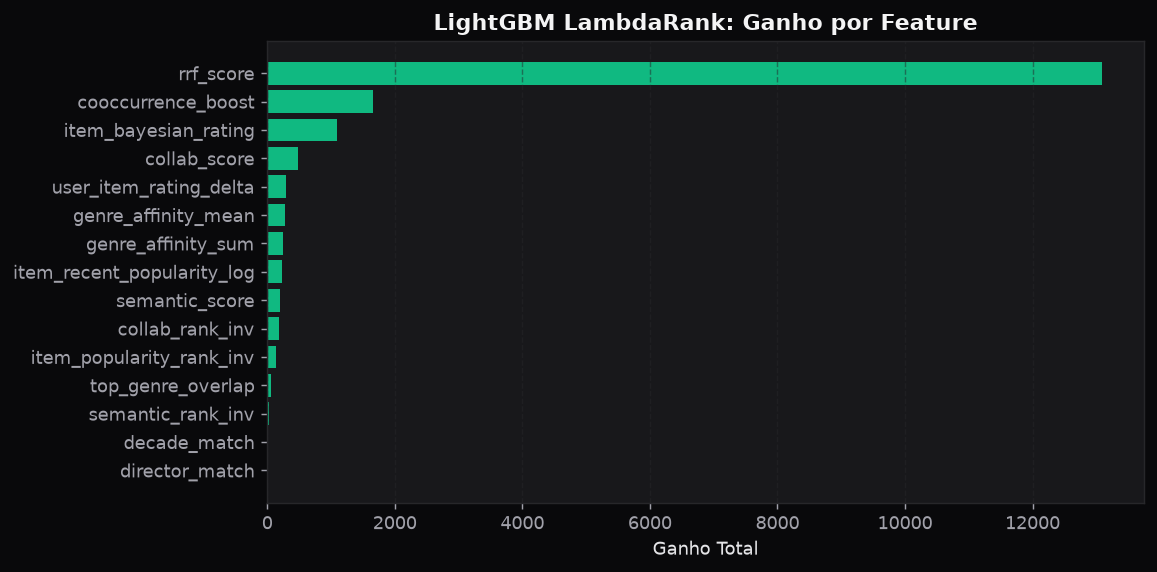

LLM call failed (The read operation timed out); triggering deterministic fallback.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2954.12it/s]

LLM call failed (The read operation timed out); triggering deterministic fallback.


Telemetry: {'request_id': 'f271156d-260', 'retrieval_ms': 5465.583, 'ranking_ms': 5.365, 'llm_ms': 16049.274, 'total_ms': 21520.222, 'candidates_retrieved': 100, 'candidates_after_filters': 24, 'final_returned': 5, 'feature_store_backend': 'duckdb_memory', 'feature_store_hit': True, 'llm_provider_used': 'gemini', 'llm_fallback_triggered': True, 'fallback_reason': 'api_error:ReadTimeout', 'guardrail_rejected_ids': [], 'estimated_prompt_tokens': 1196, 'estimated_completion_tokens': 0}


,Rank,Title,Director,Runtime,Genres,LGBM_Score,Explanation
0,1,The Departed (2006),Unknown,124m,"Crime, Drama, Thriller",-0.38494,"Shares Crime, Drama DNA with The Three Caballe..."
1,2,Munich (2005),Unknown,124m,"Action, Crime, Drama, Thriller",-0.73388,Shares Action DNA with The Three Caballeros (1...
2,3,Blink (1994),Unknown,108m,Thriller,-1.06468,Shares Thriller DNA with The Three Caballeros ...
3,4,Time Lapse (2014),Unknown,124m,"Crime, Drama, Sci-Fi, Thriller",-1.05947,"Shares Crime, Drama DNA with The Three Caballe..."
4,5,13 Tzameti (2005),Unknown,108m,"Film-Noir, Thriller",-1.09445,"Shares Film-Noir, Thriller DNA with The Three ..."


In [5]:
orchestrator = KinoRankAgentOrchestrator()
booster = orchestrator.ranker.booster
gains = booster.feature_importance(importance_type="gain")
imp_df = pd.DataFrame({
    "Feature": FEATURE_NAMES,
    "Gain_Importance": gains,
}).sort_values("Gain_Importance", ascending=True)

fig, ax = plt.subplots(figsize=(9, 4.5), dpi=130)
ax.barh(imp_df["Feature"], imp_df["Gain_Importance"], color="#10b981")
ax.set_title("LightGBM LambdaRank: Ganho por Feature", fontweight="bold")
ax.set_xlabel("Ganho Total")
ax.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

response = orchestrator.recommend(
    user_id=1,
    query="thriller psicológico estilo Fincher, < 135 min, depois de 1994, sem terror",
    top_k=5,
)
print(f"Telemetry: {response.telemetry.model_dump()}")
pd.DataFrame([
    {
        "Rank": r.rank,
        "Title": f"{r.title} ({r.release_year})",
        "Director": r.director,
        "Runtime": f"{r.runtime_minutes}m",
        "Genres": ", ".join(r.genres),
        "LGBM_Score": r.lgbm_score,
        "Explanation": r.explanation,
    }
    for r in response.recommendations
])

## Resultados

Avaliação comparativa das 5 abordagens nos 604 usuários do conjunto de teste temporal.

,model,NDCG@10,Recall@20,MAP@10,Catalog_Coverage_%,ColdStart_HitRate@10,ILD@10,Latency_p50_ms,Latency_p95_ms
0,Popularity Baseline,0.0515,0.0620,0.0280,2.50,0.1738,0.3599,0.01,0.02
1,Collaborative-Only (ALS),0.0574,0.1181,0.0277,31.48,0.1474,0.3328,0.19,0.60
2,Semantic-Only (FAISS),0.0082,0.0173,0.0038,32.17,0.0712,0.1967,0.89,1.26
3,Hybrid Two-Stage (RRF + LightGBM),0.0642,0.1002,0.0323,28.94,0.1556,0.3379,6.35,8.47
4,Hybrid + MMR (Full KinoRank),0.0648,0.1012,0.0325,28.84,0.1573,0.3421,12.16,14.93


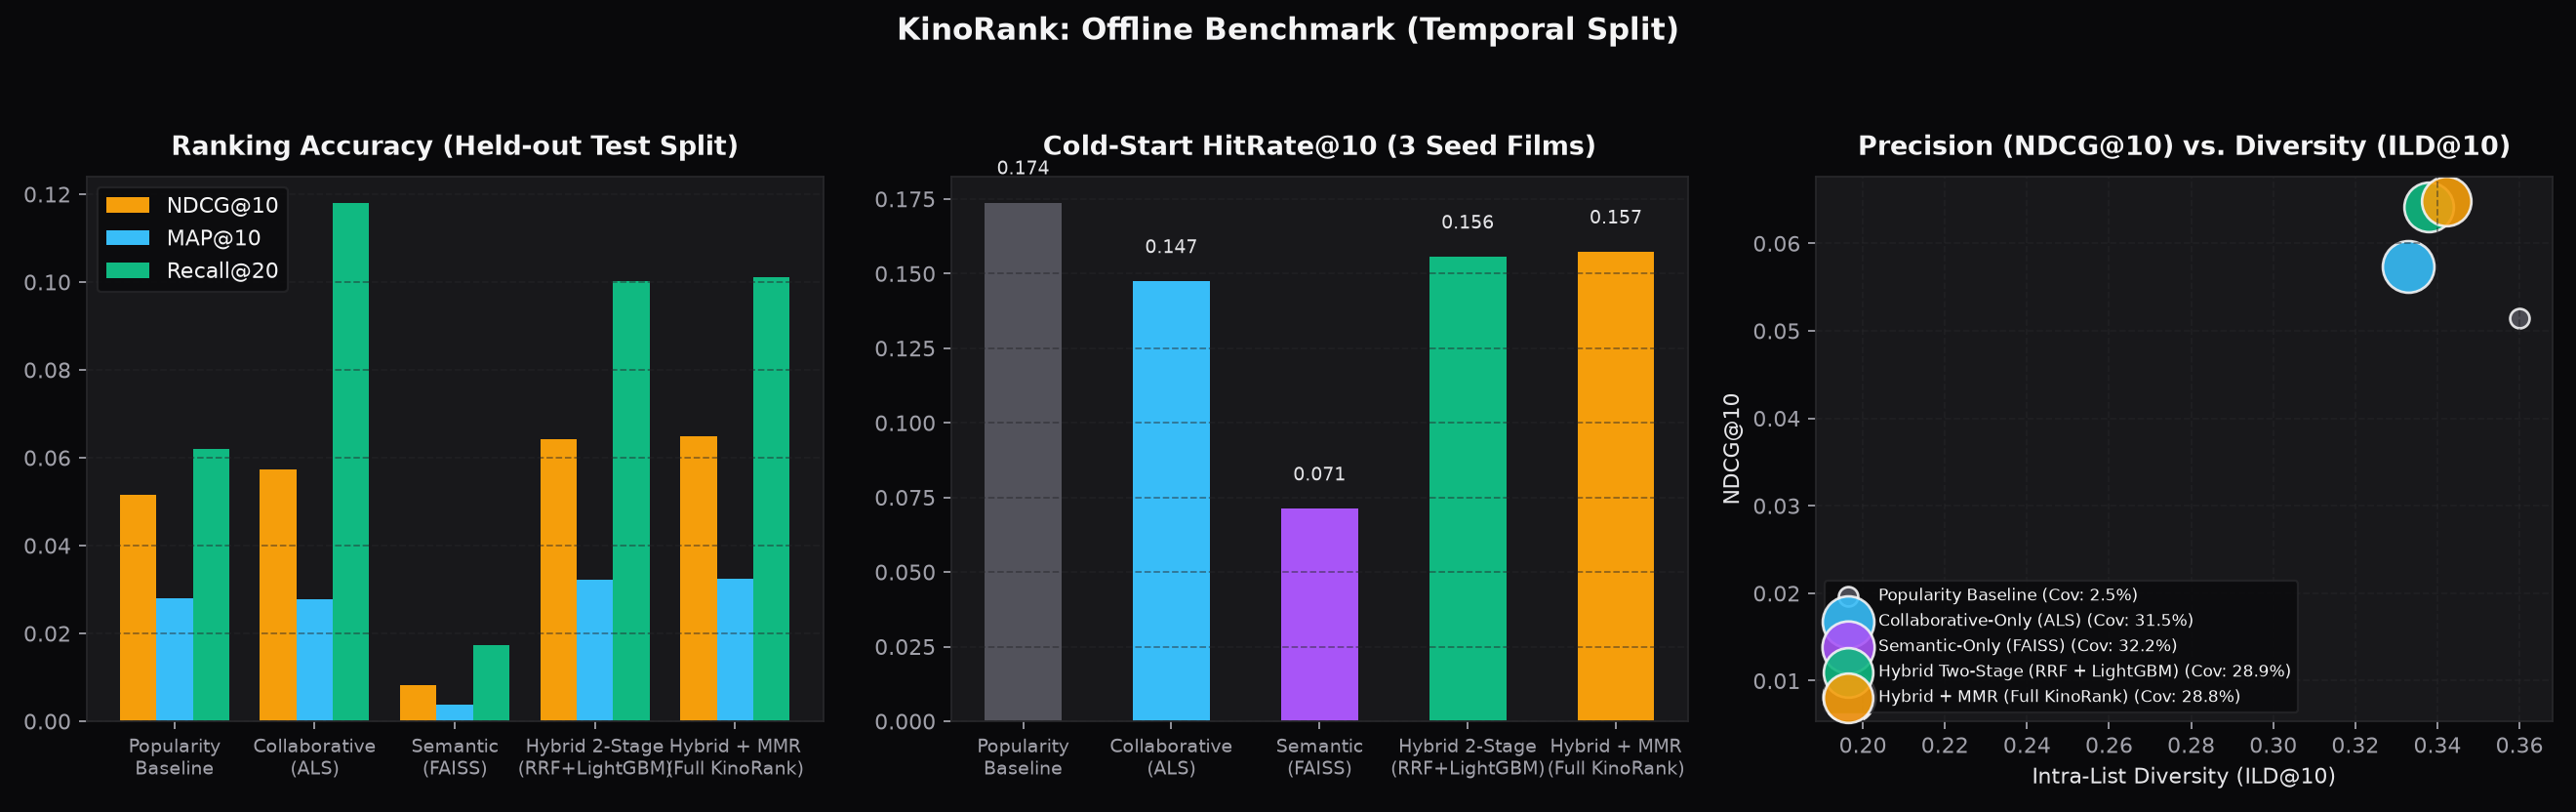

In [6]:
import json
from IPython.display import Image, display

bench_json = json.loads((settings.metrics_dir / "benchmark_results.json").read_text(encoding="utf-8"))
bench_df = pd.DataFrame(bench_json["results"])
display(bench_df)

chart_path = settings.metrics_dir / "benchmark_comparison.png"
if chart_path.exists():
    display(Image(filename=str(chart_path)))